In [1]:
from pathlib import Path
import torch
import torchvision
import pandas as pd

PROJECT_DIR = Path(r"E:\PlantVillage")
DATA_DIR = PROJECT_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
MODEL_DIR = PROJECT_DIR / "models" / "resnet18"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

print("\nMetadata files:")
for name in [
    "train_metadata.csv",
    "val_metadata.csv",
    "test_metadata.csv"
]:
    path = PROCESSED_DIR / name
    print(f"{name}: {path.exists()}")

print("\nImage directory exists:", (DATA_DIR / "images").exists())
print("ResNet18 model directory:", MODEL_DIR)

PyTorch: 2.13.0+cu130
Torchvision: 0.28.0+cu130
Device: cuda

Metadata files:
train_metadata.csv: True
val_metadata.csv: False
test_metadata.csv: True

Image directory exists: True
ResNet18 model directory: E:\PlantVillage\models\resnet18


In [2]:
import torch
import torch.nn as nn
from torchvision import models

# Use the GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load ResNet18 with pretrained ImageNet weights
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace the final layer: 1000 ImageNet classes -> 38 plant classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 38)

# Move model to GPU
model = model.to(device)

# Verify the model
print("Model: ResNet18")
print("Device:", device)
print("Number of output classes:", model.fc.out_features)
print("Final layer:", model.fc)
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ANUJA/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:03<00:00, 15.4MB/s]


Model: ResNet18
Device: cuda
Number of output classes: 38
Final layer: Linear(in_features=512, out_features=38, bias=True)
Total parameters: 11196006
Trainable parameters: 11196006


In [3]:
from pathlib import Path

for folder in [
    Path(r"E:\PlantVillage\data\processed"),
    Path(r"E:\PlantVillage\data"),
]:
    print(f"\nSearching in: {folder}")

    if folder.exists():
        for path in folder.rglob("*val*"):
            if path.is_file():
                print(path)


Searching in: E:\PlantVillage\data\processed
E:\PlantVillage\data\processed\validation_metadata.csv

Searching in: E:\PlantVillage\data
E:\PlantVillage\data\processed\validation_metadata.csv


In [4]:
import pandas as pd

train_df = pd.read_csv(PROCESSED_DIR / "train_metadata.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation_metadata.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test_metadata.csv")

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nColumns:", train_df.columns.tolist())
print("Training classes:", train_df["label"].nunique())
print("Validation classes:", val_df["label"].nunique())
print("Test classes:", test_df["label"].nunique())

print("\nSample rows:")
display(train_df.head())

Training samples: 39236
Validation samples: 4360
Test samples: 10704

Columns: ['image_path', 'label']
Training classes: 38
Validation classes: 38
Test classes: 38

Sample rows:


,image_path,label
0,E:\PlantVillage\data\images\Soybean___healthy\...,Soybean___healthy
1,E:\PlantVillage\data\images\Tomato___Late_blig...,Tomato___Late_blight
2,E:\PlantVillage\data\images\Potato___healthy\b...,Potato___healthy
3,E:\PlantVillage\data\images\Grape___Leaf_bligh...,Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
4,E:\PlantVillage\data\images\Grape___Esca_(Blac...,Grape___Esca_(Black_Measles)


In [5]:
from torchvision import transforms

IMAGE_SIZE = 224

# ImageNet normalization values
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Training: augmentation + normalization
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Validation and test: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("Image size:", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Training augmentation: horizontal flip + rotation")
print("Validation/test augmentation: disabled")
print("Normalization: ImageNet mean and standard deviation")

Image size: 224 x 224
Training augmentation: horizontal flip + rotation
Validation/test augmentation: disabled
Normalization: ImageNet mean and standard deviation


In [6]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Create a consistent mapping for all 38 classes
classes = sorted(train_df["label"].unique())
class_to_idx = {name: idx for idx, name in enumerate(classes)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

class PlantVillageDataset(Dataset):
    def __init__(self, dataframe, transform, class_to_idx):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = self.class_to_idx[row["label"]]

        return image, label

# Create datasets
train_dataset = PlantVillageDataset(
    train_df, train_transform, class_to_idx
)
val_dataset = PlantVillageDataset(
    val_df, eval_transform, class_to_idx
)
test_dataset = PlantVillageDataset(
    test_df, eval_transform, class_to_idx
)

# Create DataLoaders
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=True
)

print("Classes:", len(classes))
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Classes: 38
Training samples: 39236
Validation samples: 4360
Test samples: 10704
Batch size: 16
Training batches: 2453
Validation batches: 273
Test batches: 669


In [7]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Image values finite:", torch.isfinite(images).all().item())
print("Label range:", labels.min().item(), "to", labels.max().item())

assert images.shape == (16, 3, 224, 224)
assert labels.shape == (16,)
assert torch.isfinite(images).all()
assert labels.min() >= 0 and labels.max() < 38

print("\nBatch validation passed!")

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image dtype: torch.float32
Label dtype: torch.int64
Image values finite: True
Label range: 15 to 35

Batch validation passed!


In [8]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from pathlib import Path

# Training configuration
EPOCHS = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 3

BEST_MODEL_PATH = MODEL_DIR / "best_resnet18.pth"
HISTORY_PATH = MODEL_DIR / "training_history.csv"

# Freeze all pretrained parameters
for param in model.parameters():
    param.requires_grad = False

# Train only the newly replaced classification layer
for param in model.fc.parameters():
    param.requires_grad = True

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = AdamW(
    model.fc.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

# Verify configuration
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Model: ResNet18")
print("Device:", device)
print("Epoch limit:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Early-stopping patience:", PATIENCE)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Checkpoint path:", BEST_MODEL_PATH)
print("Loss function: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Scheduler: ReduceLROnPlateau")

Model: ResNet18
Device: cuda
Epoch limit: 10
Learning rate: 0.001
Weight decay: 0.0001
Early-stopping patience: 3
Total parameters: 11,196,006
Trainable parameters: 19,494
Checkpoint path: E:\PlantVillage\models\resnet18\best_resnet18.pth
Loss function: CrossEntropyLoss
Optimizer: AdamW
Scheduler: ReduceLROnPlateau


In [9]:
import time
import torch

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    # Keep the frozen pretrained backbone in evaluation mode
    # so BatchNorm running statistics do not change.
    for name, module in model.named_modules():
        if name.startswith(("conv1", "bn1", "layer1", "layer2", "layer3", "layer4")):
            module.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    start_time = time.time()

    for batch_idx, (images, labels) in enumerate(loader, start=1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

        if batch_idx % 200 == 0 or batch_idx == len(loader):
            print(
                f"Batch {batch_idx}/{len(loader)} | "
                f"Loss: {running_loss / total:.4f} | "
                f"Elapsed: {(time.time() - start_time) / 60:.1f} min"
            )

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return running_loss / total, correct / total


print("Training and validation functions defined successfully.")

Training and validation functions defined successfully.


In [10]:
import copy
import time
import pandas as pd
import torch

history = []
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

EPOCHS = 10

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    scheduler.step(val_loss)

    elapsed = (time.time() - epoch_start) / 60

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "time_minutes": elapsed,
    }
    history.append(record)

    print(f"\nEpoch {epoch}/{EPOCHS}")
    print(f"Training loss:     {train_loss:.4f}")
    print(f"Training accuracy: {train_acc * 100:.2f}%")
    print(f"Validation loss:   {val_loss:.4f}")
    print(f"Validation accuracy: {val_acc * 100:.2f}%")
    print(f"Time: {elapsed:.2f} minutes")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "class_to_idx": class_to_idx,
        }, BEST_MODEL_PATH)

        print("Best checkpoint saved.")
    else:
        epochs_without_improvement += 1
        print(
            "No validation-loss improvement:",
            epochs_without_improvement,
            "/",
            PATIENCE
        )

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nResNet18 training finished.")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print("Checkpoint:", BEST_MODEL_PATH)
print("History:", HISTORY_PATH)

Batch 200/2453 | Loss: 1.9951 | Elapsed: 1.8 min
Batch 400/2453 | Loss: 1.4288 | Elapsed: 3.6 min
Batch 600/2453 | Loss: 1.1590 | Elapsed: 5.4 min
Batch 800/2453 | Loss: 0.9964 | Elapsed: 7.2 min
Batch 1000/2453 | Loss: 0.8846 | Elapsed: 9.0 min
Batch 1200/2453 | Loss: 0.7997 | Elapsed: 10.8 min
Batch 1400/2453 | Loss: 0.7349 | Elapsed: 12.6 min
Batch 1600/2453 | Loss: 0.6813 | Elapsed: 14.3 min
Batch 1800/2453 | Loss: 0.6383 | Elapsed: 16.1 min
Batch 2000/2453 | Loss: 0.6026 | Elapsed: 17.9 min
Batch 2200/2453 | Loss: 0.5721 | Elapsed: 19.8 min
Batch 2400/2453 | Loss: 0.5444 | Elapsed: 21.6 min
Batch 2453/2453 | Loss: 0.5380 | Elapsed: 22.0 min

Epoch 1/10
Training loss:     0.5380
Training accuracy: 87.02%
Validation loss:   0.2311
Validation accuracy: 93.19%
Time: 24.45 minutes
Best checkpoint saved.
Batch 200/2453 | Loss: 0.2531 | Elapsed: 1.2 min
Batch 400/2453 | Loss: 0.2523 | Elapsed: 2.4 min
Batch 600/2453 | Loss: 0.2381 | Elapsed: 3.8 min
Batch 800/2453 | Loss: 0.2377 | Elapse

RESNET18 FINAL TEST RESULTS
Test accuracy:   95.91%
Macro precision: 95.46%
Macro recall:    94.54%
Macro F1-score:  94.90%
Test images: 10704
Checkpoint epoch: 10

Classification report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.99      0.87      0.92       127
                                 Apple___Black_rot       0.98      0.97      0.97       146
                          Apple___Cedar_apple_rust       0.91      1.00      0.95        52
                                   Apple___healthy       0.94      0.97      0.95       286
                               Blueberry___healthy       0.99      0.99      0.99       324
          Cherry_(including_sour)___Powdery_mildew       0.97      0.99      0.98       219
                 Cherry_(including_sour)___healthy       0.95      1.00      0.97       123
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.78      0.93    

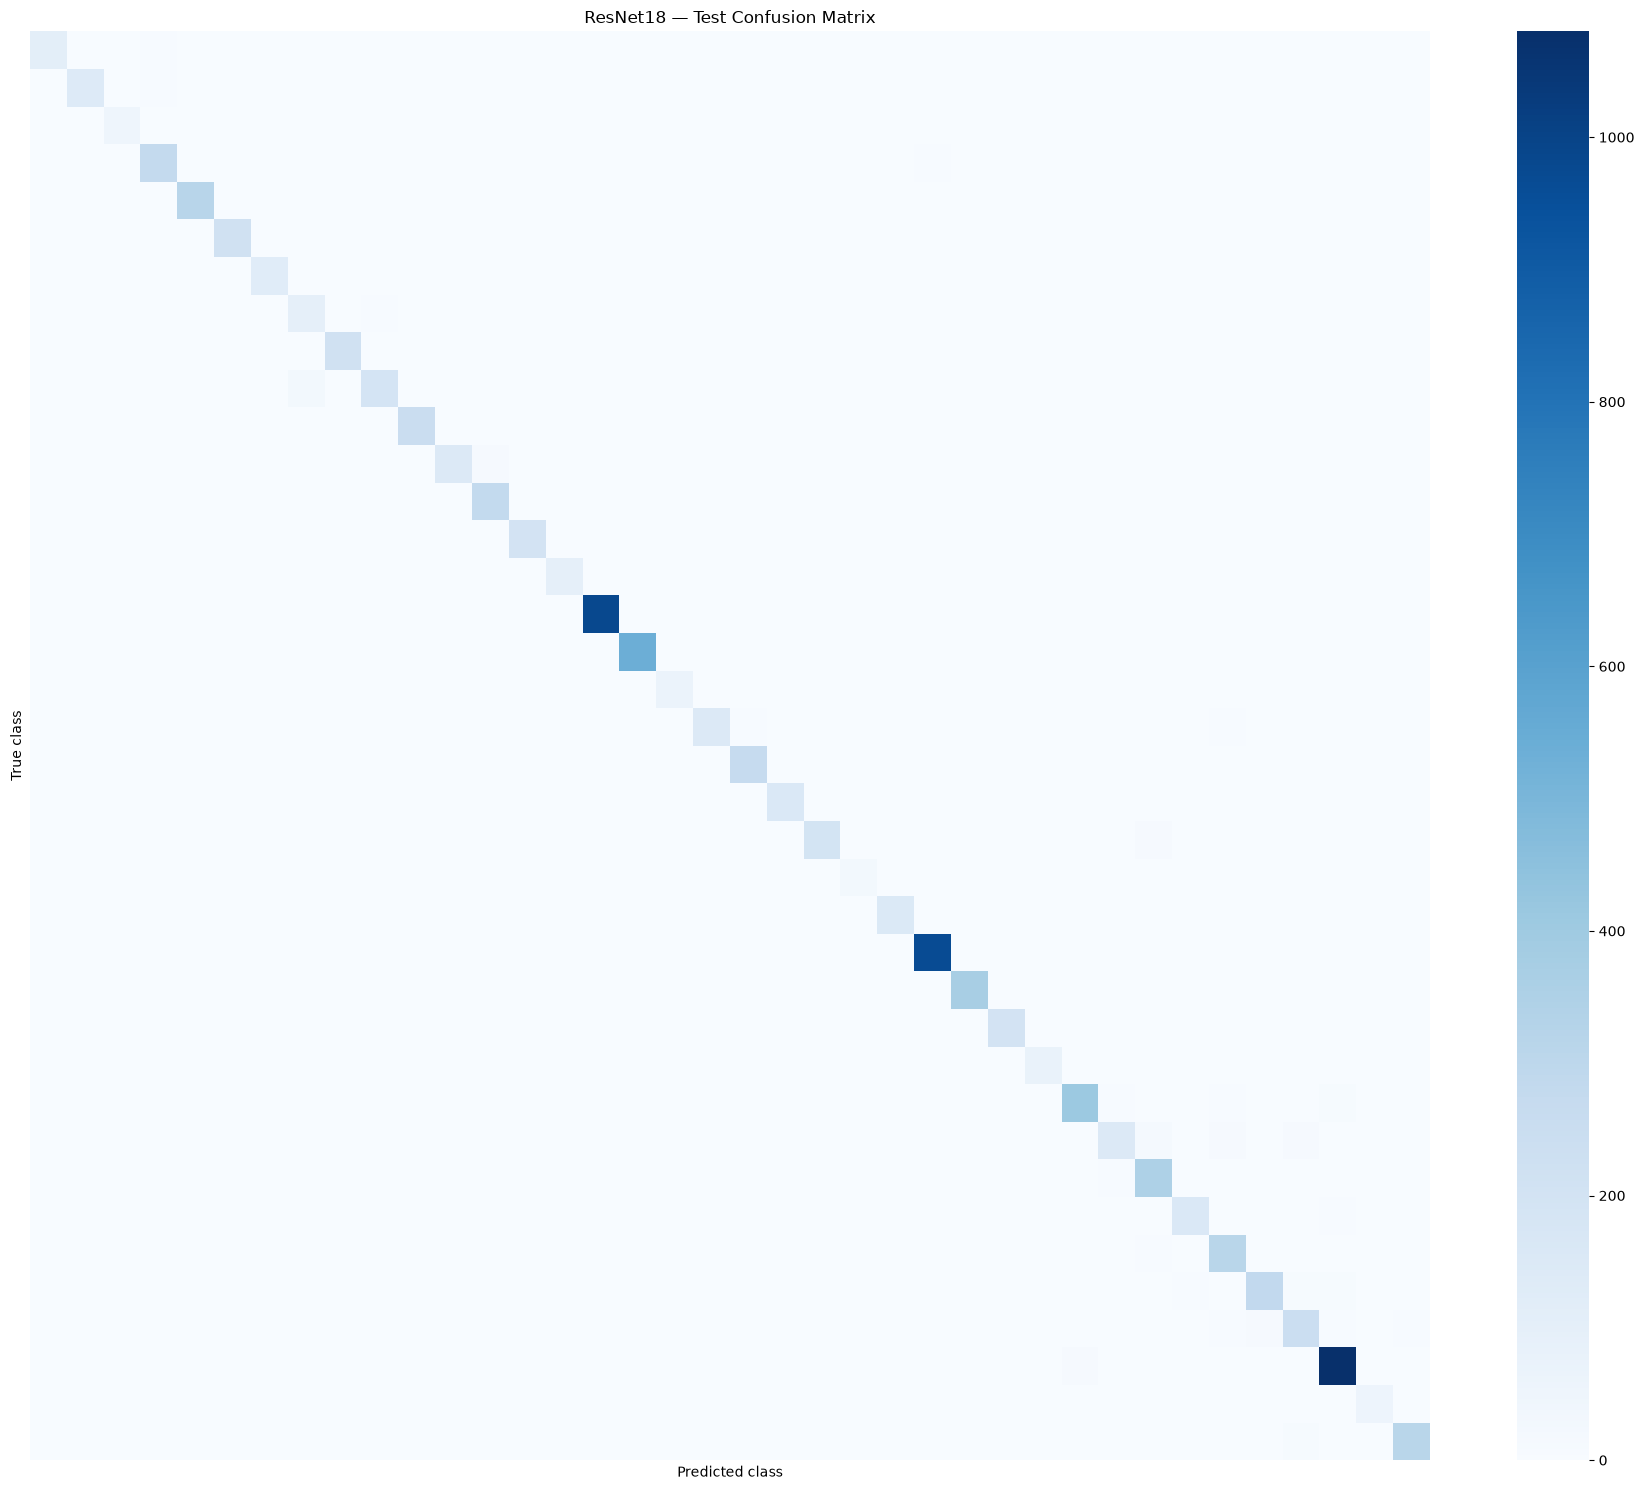

In [11]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Load the best saved checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions,
    average="macro", zero_division=0
)

print("RESNET18 FINAL TEST RESULTS")
print(f"Test accuracy:   {accuracy * 100:.2f}%")
print(f"Macro precision: {precision * 100:.2f}%")
print(f"Macro recall:    {recall * 100:.2f}%")
print(f"Macro F1-score:  {f1 * 100:.2f}%")
print("Test images:", len(all_labels))
print("Checkpoint epoch:", checkpoint["epoch"])

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(classes)))
)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=False,
    yticklabels=False
)
plt.title("ResNet18 — Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.tight_layout()
plt.show()

In [12]:
import torch
import pandas as pd

model.eval()

errors = []
correct_count = 0
total_count = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        for i in range(len(labels)):
            true_idx = labels[i].item()
            pred_idx = predictions[i].item()

            total_count += 1

            if true_idx == pred_idx:
                correct_count += 1
            else:
                errors.append({
                    "true_label": classes[true_idx],
                    "predicted_label": classes[pred_idx],
                    "true_index": true_idx,
                    "predicted_index": pred_idx
                })

print("Total test images:", total_count)
print("Correct predictions:", correct_count)
print("Incorrect predictions:", len(errors))
print(f"Recalculated accuracy: {100 * correct_count / total_count:.2f}%")

error_df = pd.DataFrame(errors)

if not error_df.empty:
    display(error_df.head(20))
    print("\nMost frequent true classes among errors:")
    display(error_df["true_label"].value_counts().head(10))
else:
    print("No misclassifications found.")

Total test images: 10704
Correct predictions: 10266
Incorrect predictions: 438
Recalculated accuracy: 95.91%


,true_label,predicted_label,true_index,predicted_index
0,Raspberry___healthy,Cherry_(including_sour)___healthy,23,6
1,Raspberry___healthy,Grape___healthy,23,14
2,Raspberry___healthy,Cherry_(including_sour)___healthy,23,6
3,Raspberry___healthy,Cherry_(including_sour)___healthy,23,6
4,Raspberry___healthy,Soybean___healthy,23,24
5,Raspberry___healthy,Cherry_(including_sour)___Powdery_mildew,23,5
6,Potato___Late_blight,Tomato___Late_blight,21,30
7,Potato___Late_blight,Tomato___Late_blight,21,30
8,Potato___Late_blight,Tomato___Late_blight,21,30
9,Potato___Late_blight,Tomato___Late_blight,21,30



Most frequent true classes among errors:


true_label
Tomato___Early_blight                            65
Tomato___Target_Spot                             45
Tomato___Spider_mites Two-spotted_spider_mite    35
Corn_(maize)___Northern_Leaf_Blight              29
Tomato___Septoria_leaf_spot                      24
Tomato___Bacterial_spot                          23
Tomato___Tomato_Yellow_Leaf_Curl_Virus           20
Tomato___Late_blight                             19
Pepper,_bell___Bacterial_spot                    18
Grape___Black_rot                                17
Name: count, dtype: int64

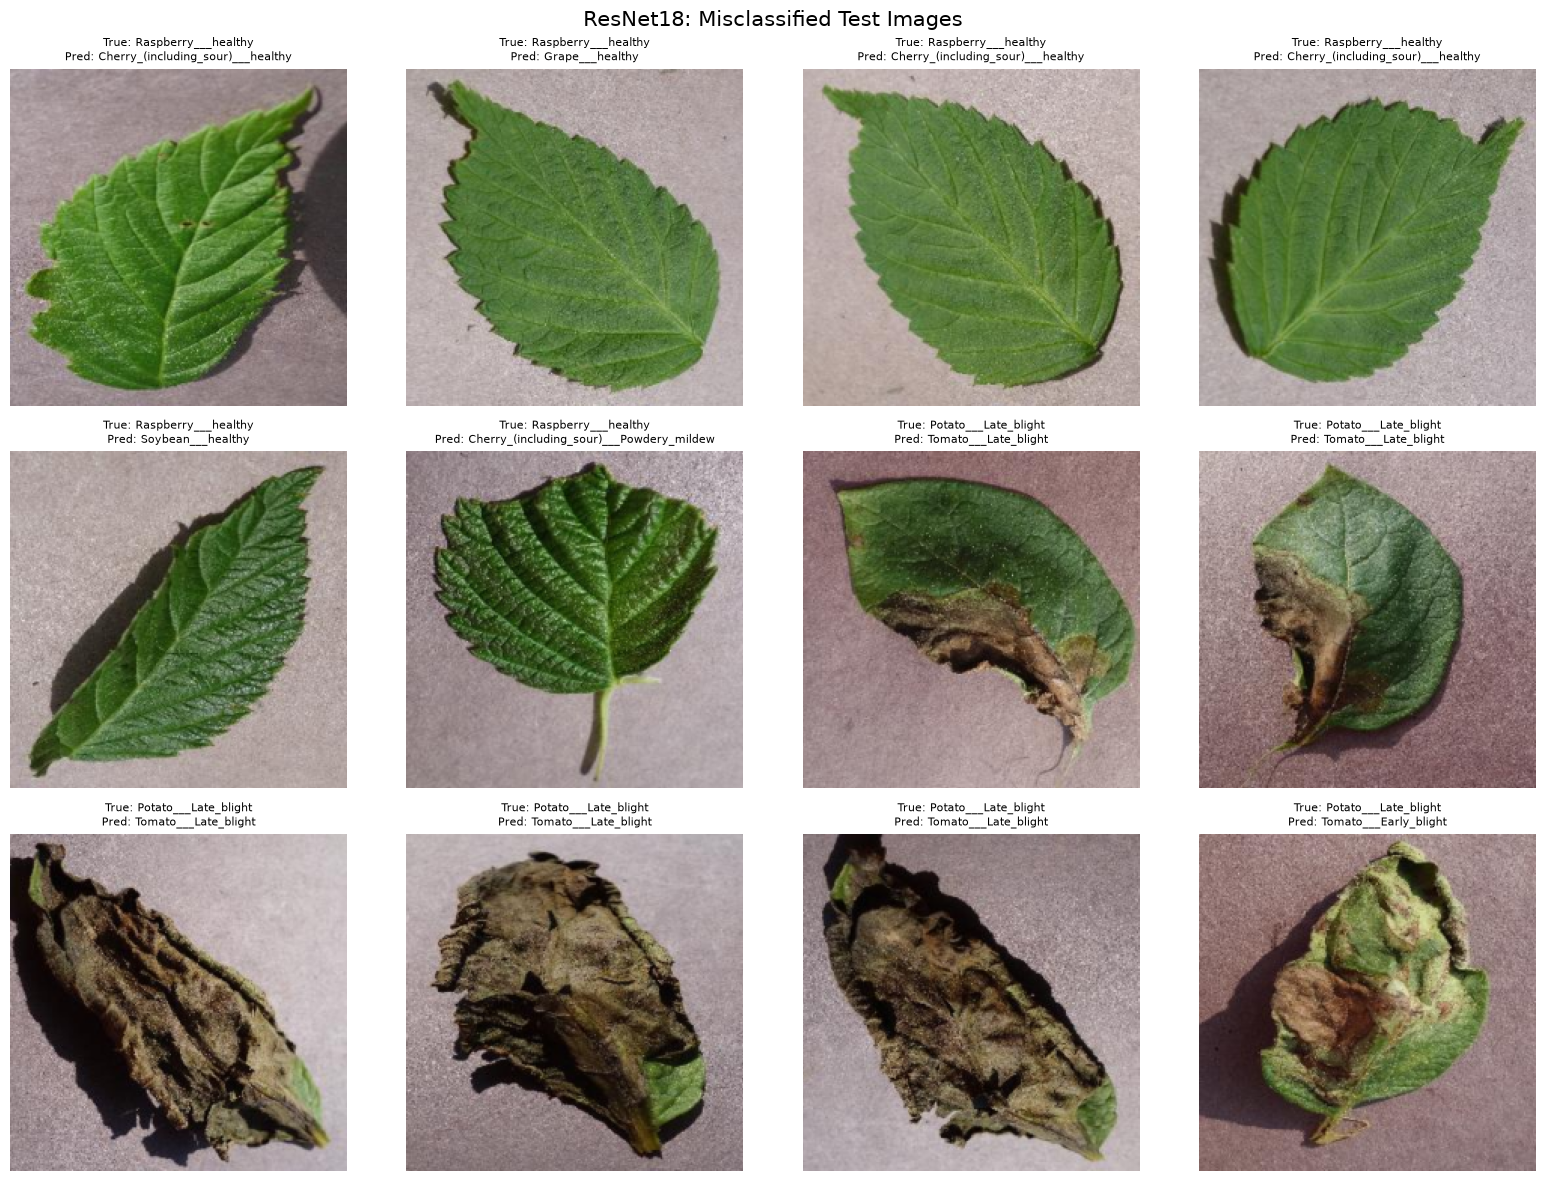

In [13]:
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Display up to 12 misclassified test images
num_to_show = min(12, len(error_df))

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

model.eval()
shown = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        for i in range(len(labels)):
            if predictions[i].item() != labels[i].item():
                # Convert normalized tensor to displayable RGB
                img = images[i].detach().cpu().clone()

                mean = torch.tensor(
                    [0.485, 0.456, 0.406]
                ).view(3, 1, 1)
                std = torch.tensor(
                    [0.229, 0.224, 0.225]
                ).view(3, 1, 1)

                img = (img * std + mean).clamp(0, 1)
                img = img.permute(1, 2, 0).numpy()

                true_idx = labels[i].item()
                pred_idx = predictions[i].item()

                axes[shown].imshow(img)
                axes[shown].set_title(
                    f"True: {classes[true_idx]}\n"
                    f"Pred: {classes[pred_idx]}",
                    fontsize=8
                )
                axes[shown].axis("off")
                shown += 1

                if shown >= num_to_show:
                    break

        if shown >= num_to_show:
            break

for j in range(shown, len(axes)):
    axes[j].axis("off")

plt.suptitle("ResNet18: Misclassified Test Images", fontsize=15)
plt.tight_layout()
plt.show()